# The Heston Stochastic Volatility Model

In the Black-Scholes model volatility is constant, which cannot reproduce the volatility smile
and skew observed on option markets. The Heston (1993) model makes the variance $v_t$ random,
mean-reverting, and correlated with the underlying:

$$
\begin{cases}
\dfrac{dS_t}{S_t} = (r - q)\,dt + \sqrt{v_t}\, dW_t^S & \text{(price dynamics)} \\[2mm]
dv_t = \kappa(\theta - v_t)\,dt + \xi \sqrt{v_t}\, dW_t^v & \text{(variance dynamics)} \\[2mm]
d\langle W^S, W^v \rangle_t = \rho\, dt
\end{cases}
$$

| Parameter | Description |
|-----------|-------------|
| $v_0$ | Initial variance |
| $\kappa$ | Speed of mean reversion of the variance |
| $\theta$ | Long-term variance |
| $\xi$ | Volatility of the variance ("vol of vol") |
| $\rho$ | Correlation between the two Brownian motions |
| $r, q$ | Risk-free rate and continuous dividend yield |

The correlation $\rho$ depends strongly on the asset class. For stocks and equity indices it is usually
strongly negative (around $-0.6$ to $-0.8$). This is the *leverage effect*: a sharp fall in prices comes
with panic, which drives volatility up, so price and volatility move in opposite directions.

This notebook:
1. simulates the variance process,
2. prices options by Monte Carlo,
3. prices options in semi-closed form with the characteristic function (Fourier inversion),
4. recovers the implied volatility smile, skew and surface generated by the model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import norm
from scipy.integrate import quad
from scipy.optimize import brentq

rng = np.random.default_rng(seed=1)  # fixed seed for reproducible results

## 1. Simulating the variance

The variance process is discretised with an Euler scheme:

$$
v_{t+\Delta t} = v_t + \kappa(\theta - v_t^+)\,\Delta t + \xi \sqrt{v_t^+}\,\sqrt{\Delta t}\, Z, \qquad Z \sim \mathcal{N}(0,1)
$$

The Euler scheme can produce negative variances, which have no meaning and make $\sqrt{v_t}$ undefined.
We use the *full truncation* scheme: the drift and the diffusion are computed with $v_t^+ = \max(v_t, 0)$.

In [2]:
def simulate_heston_volatility(v0, kappa, theta, xi, T, N, rng=rng):
    dt = T / N
    v = np.zeros(N + 1)
    v[0] = v0

    for i in range(1, N + 1):
        v_pos = max(v[i - 1], 0.0)  # full truncation
        v[i] = v[i - 1] + kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos) * np.sqrt(dt) * rng.standard_normal()

    return np.sqrt(np.maximum(v, 0.0))  # volatility = square root of the variance

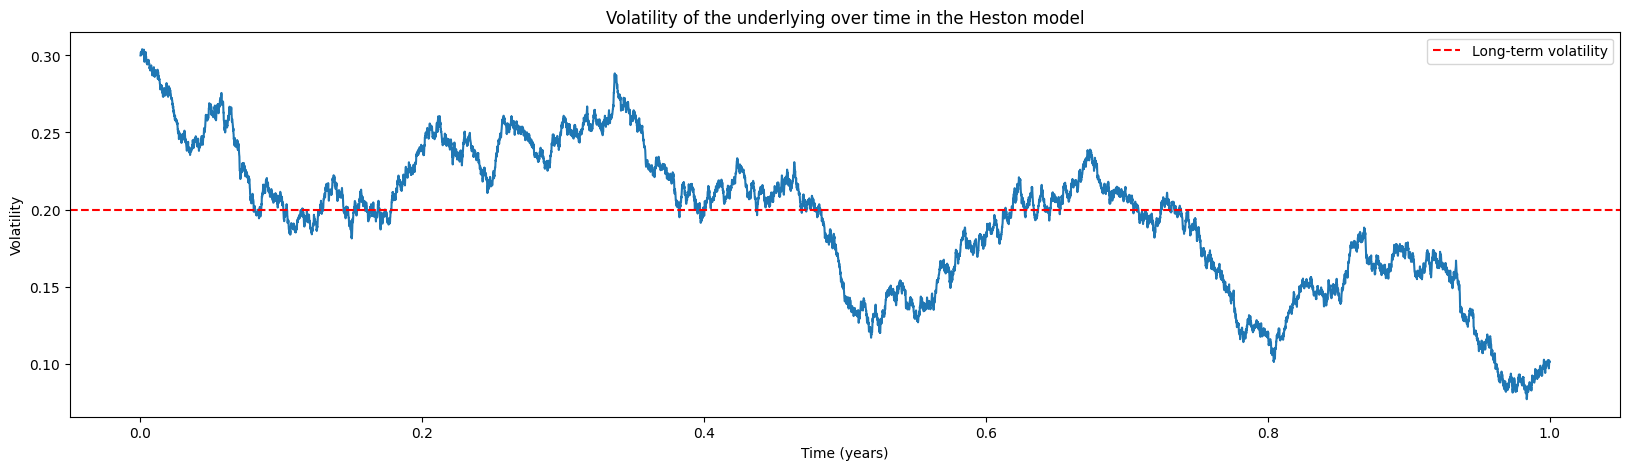

In [3]:
# Parameters
v0 = 0.09      # initial variance (volatility of 30%)
kappa = 2
theta = 0.04   # long-term variance (volatility of 20%)
xi = 0.3
T = 1
N = 10_000

vol_path = simulate_heston_volatility(v0, kappa, theta, xi, T, N)
t = np.linspace(0, T, len(vol_path))

plt.figure(figsize=(20, 5))
plt.plot(t, vol_path)
plt.axhline(y=np.sqrt(theta), color="r", linestyle="--", label="Long-term volatility")
plt.xlabel("Time (years)")
plt.ylabel("Volatility")
plt.title("Volatility of the underlying over time in the Heston model")
plt.legend(loc="best")
plt.show()

The volatility starts at 30% and is pulled back towards its long-term level of 20%.

## 2. Monte Carlo pricing

The two correlated Brownian increments are built from two independent standard normal variables $Z_1$ and $Z_2$:

$$
\begin{aligned}
\Delta W_t^v &= Z_1 \sqrt{\Delta t} \\
\Delta W_t^S &= \left( \rho Z_1 + \sqrt{1 - \rho^2}\, Z_2 \right) \sqrt{\Delta t}
\end{aligned}
$$

The log-price is updated with the same truncated variance:

$$
\ln S_{t+\Delta t} = \ln S_t + \left(r - q - \tfrac{1}{2} v_t^+\right)\Delta t + \sqrt{v_t^+}\, \Delta W_t^S
$$

The simulation runs time step by time step, vectorised over all paths, so memory use grows with the number
of paths only (and not with paths × time steps).

In [4]:
def heston_monte_carlo_price(S0, K, r, q, T, v0, kappa, theta, xi, rho, N, n_sims, option_type="call", rng=rng):
    dt = T / N
    log_S = np.full(n_sims, np.log(S0))
    v = np.full(n_sims, v0)

    for _ in range(N):
        Z1 = rng.standard_normal(n_sims)
        Z2 = rng.standard_normal(n_sims)
        dW_v = np.sqrt(dt) * Z1
        dW_S = np.sqrt(dt) * (rho * Z1 + np.sqrt(1 - rho**2) * Z2)

        v_pos = np.maximum(v, 0.0)  # full truncation
        log_S += (r - q - 0.5 * v_pos) * dt + np.sqrt(v_pos) * dW_S
        v += kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos) * dW_v

    ST = np.exp(log_S)
    if option_type == "call":
        payoff = np.maximum(ST - K, 0.0)
    elif option_type == "put":
        payoff = np.maximum(K - ST, 0.0)
    else:
        raise ValueError("option_type must be 'call' or 'put'")

    discounted = np.exp(-r * T) * payoff
    return discounted.mean(), discounted.std(ddof=1) / np.sqrt(n_sims)


def black_scholes_price(S, K, sigma, r, q, T, option_type="call"):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

Comparison of the price of an out-of-the-money call with stochastic volatility (Heston) and with a
constant volatility equal to the initial volatility (Black-Scholes).

In [5]:
# Parameters
S0 = 100
K = 115
r = 0.05
q = 0.0
v0 = 0.09
theta = 0.09
kappa = 2
xi = 0.3
rho = -0.7     # correlation between price and variance, typical of a stock
T = 1
N = 250        # time steps (about one per trading day)
n_sims = 100_000

heston_mc, heston_se = heston_monte_carlo_price(S0, K, r, q, T, v0, kappa, theta, xi, rho, N, n_sims, "call")
bs_constant_vol = black_scholes_price(S0, K, np.sqrt(v0), r, q, T, "call")

print(f"Call price, Heston model (Monte Carlo) : {heston_mc:.4f} ± {1.96 * heston_se:.4f}")
print(f"Call price, constant volatility (B-S)  : {bs_constant_vol:.4f}")
print(f"Relative difference                    : {abs(heston_mc - bs_constant_vol) / heston_mc * 100:.2f}%")

Call price, Heston model (Monte Carlo) : 7.6502 ± 0.0914
Call price, constant volatility (B-S)  : 8.3378
Relative difference                    : 8.99%


The Heston price is lower. With a negative correlation ($\rho = -0.7$), a rise in the price comes with a
fall in volatility: large upward moves become less likely than under Black-Scholes, so an out-of-the-money
call is less likely to finish in the money and is cheaper.

## 3. Semi-closed-form pricing with the characteristic function

Option prices in the Heston model can be computed almost exactly thanks to the **Fourier transform**,
using the **characteristic function** of the log-price.

### Call and put prices

The price of a **European call** $C$ is

$$C = S_0 \, e^{-q\tau} P_1 - K \, e^{-r\tau} P_2$$

and the price of the **European put** $P$ follows from **put-call parity**:

$$P = C - S_0 \, e^{-q\tau} + K \, e^{-r\tau}$$

### The probabilities $P_1$ and $P_2$

The terms $P_j$ ($j \in \{1, 2\}$) are obtained by **Fourier inversion**:

$$P_j = \frac{1}{2} + \frac{1}{\pi}
        \int_0^{+\infty}
        \Re\!\left(\frac{e^{-iu\ln K}\,\phi_j(u)}{iu}\right) du$$

### The characteristic function $\phi_j(u)$

$$\phi_j(u) = \exp\!\Big(
  iu\bigl(\ln S_0 + (r - q)\tau\bigr)
  + C_j(u,\tau)\,\theta
  + D_j(u,\tau)\,v_0
\Big)$$

**Constants for each $j$**

$$u_1 = \tfrac{1}{2}, \quad b_1 = \kappa - \rho\xi \qquad\qquad u_2 = -\tfrac{1}{2}, \quad b_2 = \kappa$$

**Intermediate variables**

$$d_j = \sqrt{\left(\rho\xi\, iu - b_j\right)^2 - \xi^2\left(2u_j\, iu - u^2\right)}, \qquad
g_j = \frac{b_j - \rho\xi\, iu - d_j}{b_j - \rho\xi\, iu + d_j}$$

**Final terms**

$$D_j(u,\tau) = \frac{b_j - \rho\xi\, iu - d_j}{\xi^2}
               \left[\frac{1 - e^{-d_j \tau}}{1 - g_j \, e^{-d_j \tau}}\right]$$

$$C_j(u,\tau) = \frac{\kappa}{\xi^2}
               \left[
                 \left(b_j - \rho\xi\, iu - d_j\right)\tau
                 - 2\ln\!\left(\frac{1 - g_j \, e^{-d_j \tau}}{1 - g_j}\right)
               \right]$$

This formulation, with $e^{-d_j\tau}$ instead of $e^{+d_j\tau}$ (Albrecher et al., *The Little Heston Trap*),
avoids discontinuities of the complex logarithm and is numerically stable for long maturities.

In [6]:
def heston_integrand(u, j, K, S0, r, q, tau, v0, kappa, theta, xi, rho):
    if j == 1:
        u_j, b_j = 0.5, kappa - rho * xi
    else:
        u_j, b_j = -0.5, kappa

    a = b_j - rho * xi * 1j * u
    d = np.sqrt(a**2 - xi**2 * (2 * u_j * 1j * u - u**2))
    g = (a - d) / (a + d)

    exp_dt = np.exp(-d * tau)
    D = (a - d) / xi**2 * (1 - exp_dt) / (1 - g * exp_dt)
    C = kappa / xi**2 * ((a - d) * tau - 2 * np.log((1 - g * exp_dt) / (1 - g)))

    phi = np.exp(1j * u * (np.log(S0) + (r - q) * tau) + C * theta + D * v0)
    return (np.exp(-1j * u * np.log(K)) * phi / (1j * u)).real


def heston_price(K, S0, r, q, tau, v0, kappa, theta, xi, rho, option_type="call"):
    if tau <= 1e-8:
        return max(S0 - K, 0.0) if option_type == "call" else max(K - S0, 0.0)

    args = (K, S0, r, q, tau, v0, kappa, theta, xi, rho)
    # The integrand is finite at u -> 0, the lower bound only avoids dividing by zero
    P1 = 0.5 + quad(heston_integrand, 1e-8, 200, args=(1, *args), limit=200, epsabs=1e-12)[0] / np.pi
    P2 = 0.5 + quad(heston_integrand, 1e-8, 200, args=(2, *args), limit=200, epsabs=1e-12)[0] / np.pi

    call = S0 * np.exp(-q * tau) * P1 - K * np.exp(-r * tau) * P2
    if option_type == "call":
        return call
    return call - S0 * np.exp(-q * tau) + K * np.exp(-r * tau)  # put-call parity

### Validation

The semi-closed-form price must fall inside the confidence interval of the Monte Carlo price computed
with the same parameters. With $\xi = 0$ the variance is deterministic, so for $v_0 = \theta$ the model
reduces to Black-Scholes with $\sigma = \sqrt{v_0}$: the two prices must coincide.

In [7]:
heston_fourier = heston_price(K, S0, r, q, T, v0, kappa, theta, xi, rho, "call")
print(f"Heston, Fourier pricing : {heston_fourier:.4f}")
print(f"Heston, Monte Carlo     : {heston_mc:.4f}  (95% CI: [{heston_mc - 1.96*heston_se:.4f}, {heston_mc + 1.96*heston_se:.4f}])")

# Limit case: almost no vol of vol and v0 = theta -> Black-Scholes
heston_limit = heston_price(K, S0, r, q, T, 0.09, kappa, 0.09, 1e-4, rho, "call")
print(f"\nHeston with xi -> 0     : {heston_limit:.4f}")
print(f"Black-Scholes (sigma=30%) : {black_scholes_price(S0, K, 0.3, r, q, T, 'call'):.4f}")

Heston, Fourier pricing : 7.6582
Heston, Monte Carlo     : 7.6502  (95% CI: [7.5588, 7.7416])

Heston with xi -> 0     : 8.3376
Black-Scholes (sigma=30%) : 8.3378


### Option price as a function of time

Price of an out-of-the-money call (K = 145) as time passes, for a fixed spot. As maturity approaches,
the time value disappears and the price of the call converges to its intrinsic value, here 0.

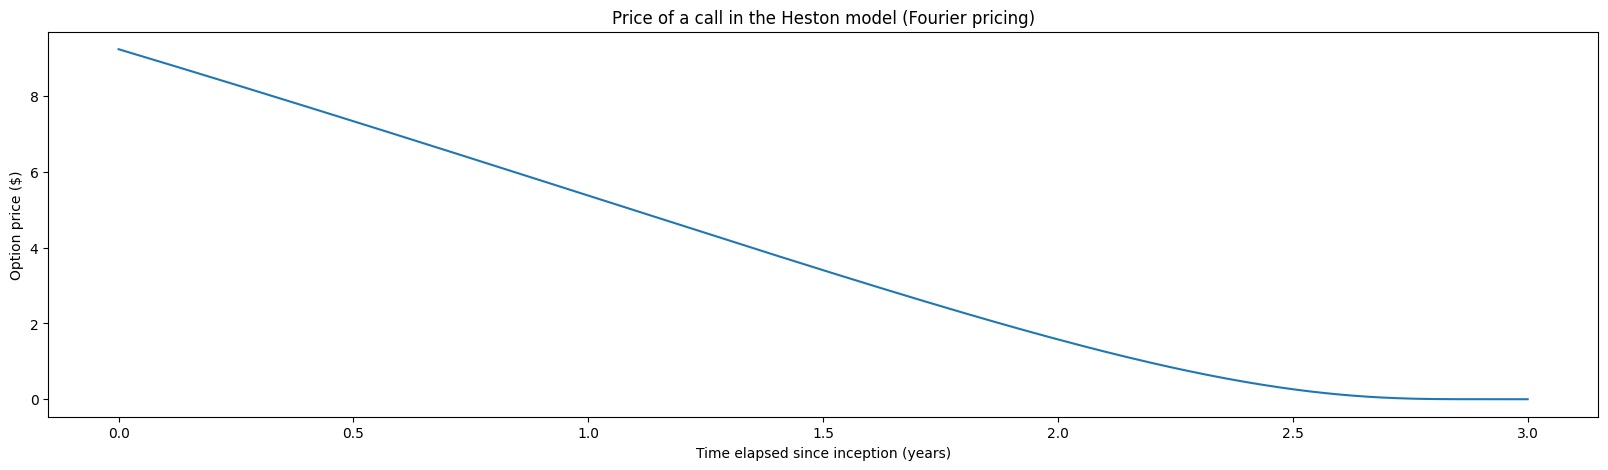

In [8]:
# Parameters
S0 = 100
K = 145
r = 0.05
q = 0.02
T = 3
v0 = 0.09
kappa = 2
theta = 0.09
xi = 0.3
rho = -0.5

t_grid = np.linspace(0, T, 300)
prices = [heston_price(K, S0, r, q, T - t, v0, kappa, theta, xi, rho, "call") for t in t_grid]

plt.figure(figsize=(20, 5))
plt.plot(t_grid, prices)
plt.xlabel("Time elapsed since inception (years)")
plt.ylabel("Option price ($)")
plt.title("Price of a call in the Heston model (Fourier pricing)")
plt.show()

## 4. Implied volatility

By inverting the Black-Scholes formula we recover the implied volatility of each Heston price,
i.e. the volatility $\sigma$ such that $BS(\sigma) = \text{Heston price}$.

The Black-Scholes price is increasing in $\sigma$, so the solution is unique. We solve the equation with
**Brent's method** on the interval $[10^{-4}, 5]$: unlike Newton-type solvers, it always converges once
the root is bracketed. If the Heston price falls outside the possible Black-Scholes prices (numerical
noise on deep out-of-the-money options), no volatility exists and we return `NaN`.

For each strike we invert the **out-of-the-money** option: a put below the forward price, a call above it.
Deep in-the-money options are almost entirely intrinsic value, so their price carries very little information
on volatility and the inversion becomes unstable. Calls and puts give the same implied volatility by put-call
parity, so this choice does not change the result, it only makes it more accurate.

In [9]:
def implied_volatility(price, S, K, r, q, T, option_type="call", low=1e-4, high=5.0):
    def objective(sigma):
        return black_scholes_price(S, K, sigma, r, q, T, option_type) - price

    if objective(low) * objective(high) > 0:  # no root in the interval
        return np.nan
    return brentq(objective, low, high, xtol=1e-10)


def heston_implied_vols(S0, strikes, r, q, T, v0, kappa, theta, xi, rho):
    forward = S0 * np.exp((r - q) * T)
    ivs = []
    for K in strikes:
        # Use the out-of-the-money option: put below the forward, call above it
        option_type = "put" if K < forward else "call"
        price = heston_price(K, S0, r, q, T, v0, kappa, theta, xi, rho, option_type)
        ivs.append(implied_volatility(price, S0, K, r, q, T, option_type))
    return np.array(ivs)

### Smile ($\rho = 0$)

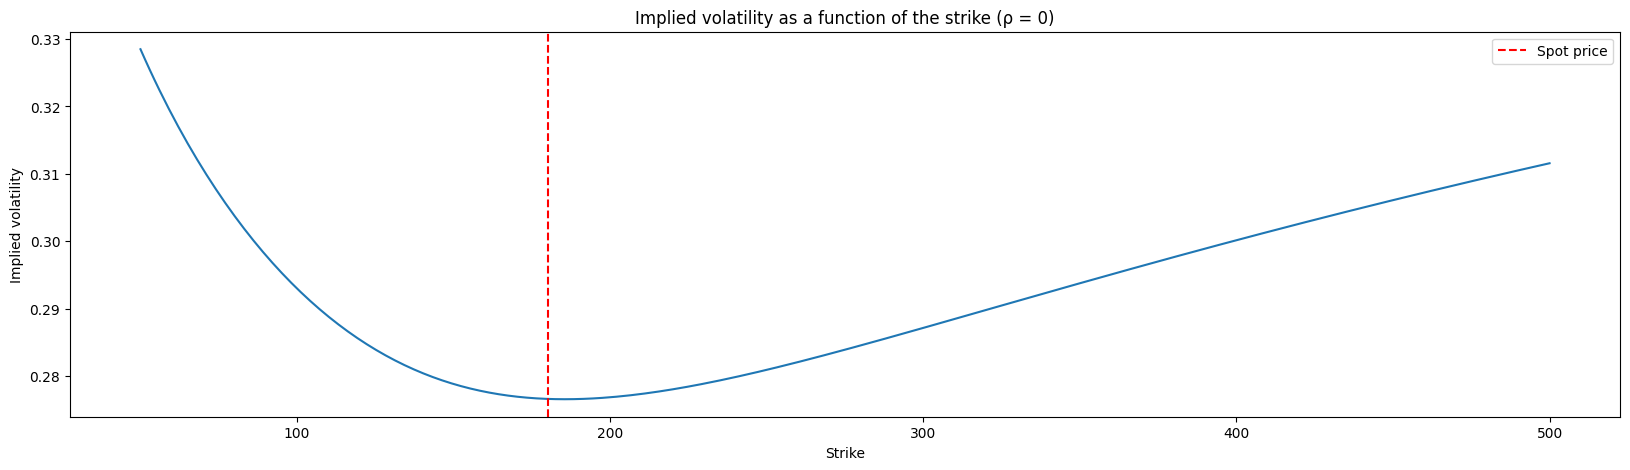

In [10]:
# Parameters
S0 = 180
r = 0.05
q = 0.02
T = 1
v0 = 0.09
kappa = 2
theta = 0.07
xi = 0.3

strikes = np.linspace(50, 500, 300)
iv_smile = heston_implied_vols(S0, strikes, r, q, T, v0, kappa, theta, xi, rho=0.0)

plt.figure(figsize=(20, 5))
plt.plot(strikes, iv_smile)
plt.axvline(x=S0, color="r", linestyle="--", label="Spot price")
plt.xlabel("Strike")
plt.ylabel("Implied volatility")
plt.title("Implied volatility as a function of the strike (ρ = 0)")
plt.legend(loc="best")
plt.show()

With $\rho = 0$, implied volatility is lowest near the money and rises on both sides: the volatility smile.

### Skew ($\rho = -0.6$)

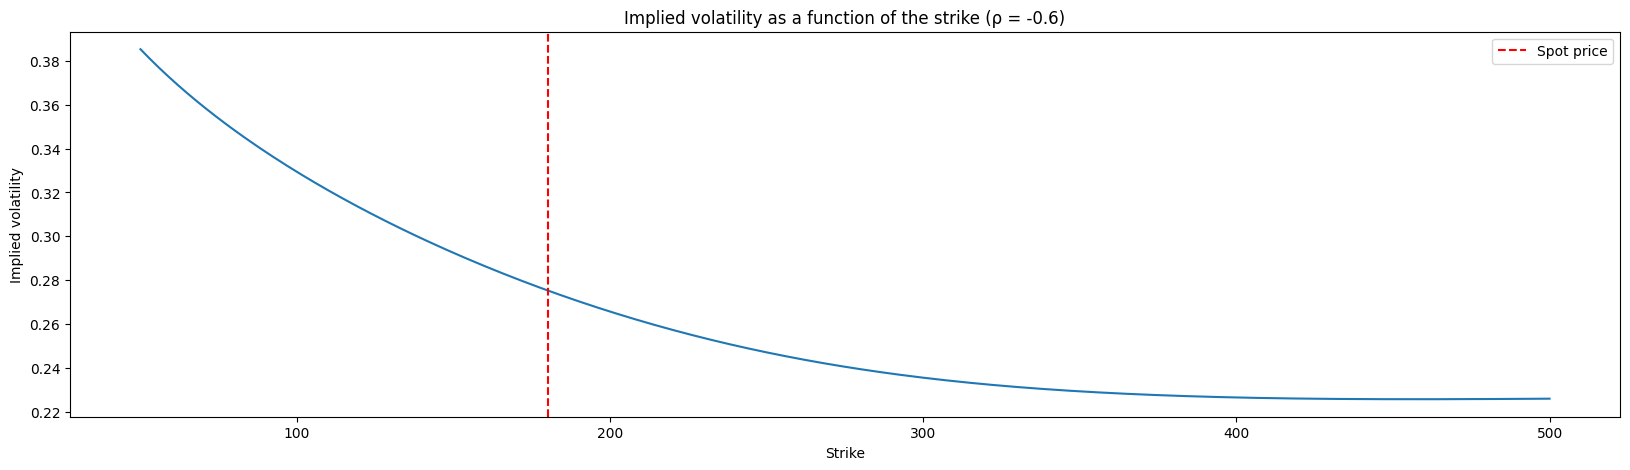

In [11]:
iv_skew = heston_implied_vols(S0, strikes, r, q, T, v0, kappa, theta, xi, rho=-0.6)

plt.figure(figsize=(20, 5))
plt.plot(strikes, iv_skew)
plt.axvline(x=S0, color="r", linestyle="--", label="Spot price")
plt.xlabel("Strike")
plt.ylabel("Implied volatility")
plt.title("Implied volatility as a function of the strike (ρ = -0.6)")
plt.legend(loc="best")
plt.show()

With $\rho = -0.6$, typical of equity markets, low strikes have a much higher implied volatility than high strikes:
this is the skew. Out-of-the-money puts, which protect against a crash, are relatively expensive.

### Implied volatility surface

In [12]:
def heston_iv_surface(S0, strikes, maturities, r, q, v0, kappa, theta, xi, rho):
    surface = np.zeros((len(maturities), len(strikes)))
    for i, T in enumerate(maturities):
        # For each maturity, compute the implied volatility for every strike
        surface[i, :] = heston_implied_vols(S0, strikes, r, q, T, v0, kappa, theta, xi, rho)
    return surface

Points where no implied volatility exists: 0 / 1920


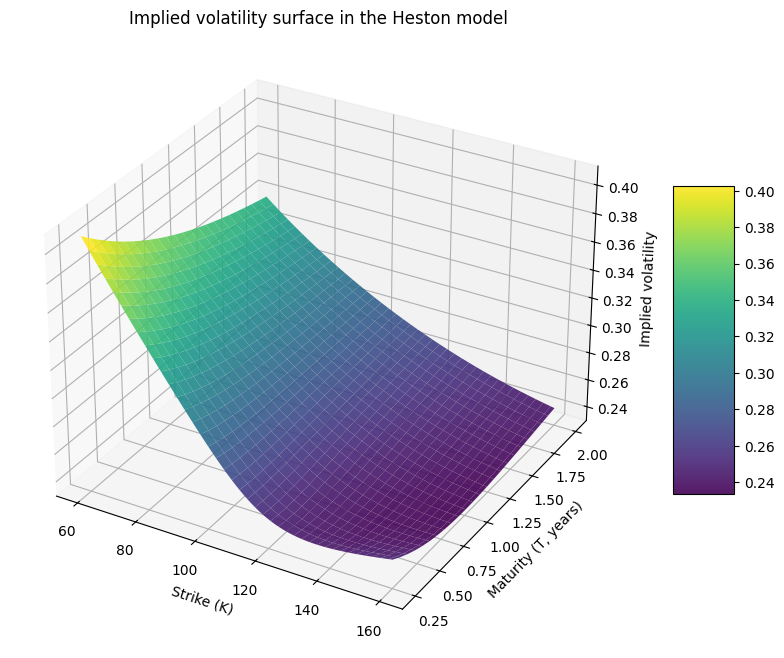

In [13]:
# Parameters
S0 = 100
r = 0.05
q = 0.02
v0 = 0.09
kappa = 2
theta = 0.09
xi = 0.6
rho = -0.6

maturities = np.linspace(0.25, 2, 24)
strikes = np.linspace(60, 160, 80)
iv_surface = heston_iv_surface(S0, strikes, maturities, r, q, v0, kappa, theta, xi, rho)
print(f"Points where no implied volatility exists: {np.isnan(iv_surface).sum()} / {iv_surface.size}")

K_grid, T_grid = np.meshgrid(strikes, maturities)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(K_grid, T_grid, iv_surface, cmap=cm.viridis, edgecolor="none", alpha=0.9)

ax.set_xlabel("Strike (K)")
ax.set_ylabel("Maturity (T, years)")
ax.set_zlabel("Implied volatility")
ax.set_title("Implied volatility surface in the Heston model")
fig.colorbar(surf, shrink=0.5, aspect=5)
ax.view_init(elev=30, azim=300)  # viewing angle chosen to show the skew

plt.show()

With $\rho = -0.6$ the skew is visible on the whole surface: deep out-of-the-money puts (low strikes) have
a higher implied volatility than deep out-of-the-money calls (high strikes). The skew is steepest for short
maturities and flattens as maturity increases.

The grid stops at strike 160 and maturity 3 months on purpose: further out, out-of-the-money call prices
fall below $10^{-6}$ and the numerical error of the Fourier integral becomes larger than the price itself,
so no implied volatility can be recovered reliably.